## 1. Setup
Libraries to set up for our analysis (we downloaded more than necessary to make sure we were going to be covered in any analysis that we wanted to do!)

In [1]:
import sys
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if "google.colab" in sys.modules:  # the project folder in Drive holds utils/ and data/raw/
    from google.colab import drive
    drive.mount("/content/drive")
    sys.path.insert(0, "/content/drive/MyDrive/Pricing the Unicorn")

from utils import prepare, features, detect, summaries, plots

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.0f}" if float(x).is_integer() and abs(x) >= 1 else f"{x:,.3f}")
plots.use_style()

### Load the source data
**Sources.** All three files come from the open **nflverse** project, which redistributes
Pro-Football-Reference tables (github.com/nflverse/nflverse-data, releases `combine`, `draft_picks`, `players`):

| File | Contents |
|---|---|
| `combine.csv` | Every combine prospect 2000–2026: height, weight, 40-yard dash, bench, vertical, broad jump, 3-cone, shuttle, and draft slot |
| `draft_picks.csv` | Every draft pick since 1980 with career weighted Approximate Value (AV), games, starts, Pro Bowls |
| `players.csv` | NFL roster positions, used to resolve generic combine labels (OL, DL, DB) |

nflverse updates these files during the season, so we use the **October 2026 snapshot** stored in the
replication zip. The checksums below confirm the files are exactly the ones the paper used.

In [2]:
prepare.verify_snapshot()
print("All three source files verified.")

raw = prepare.load_raw()
display(summaries.raw_overview(raw))
display(raw["combine"][["season", "player_name", "pos", "school", "ht", "wt", "forty", "vertical", "draft_ovr"]].head())

All three source files verified.


,rows,columns
combine,8968,18
draft_picks,12927,36
players,24844,39


,season,player_name,pos,school,ht,wt,forty,vertical,draft_ovr
0,2000,John Abraham,OLB,South Carolina,6-4,252,4.550,NaN,13
1,2000,Shaun Alexander,RB,Alabama,6-0,218,4.580,NaN,19
2,2000,Darnell Alford,OT,Boston Col.,6-4,334,5.560,25,188
3,2000,Kyle Allamon,TE,Texas Tech,6-2,253,4.970,29,NaN
4,2000,Rashard Anderson,CB,Jackson State,6-2,206,4.550,34,23


## 2. Build the modelling sample
Steps, each logged below:
1. Convert height from `"6-4"` to inches.
2. The combine file has no draft slots for 2026 yet, so 2026 prospects are matched to the draft file by exact name.
3. Attach each drafted player's career AV by (draft year, overall pick), and his NFL roster position.
4. **Namesakes**: the source occasionally gives one draft pick to two same-named prospects. We keep the one whose
   position family matches the drafted position.
5. Assign 11 position groups (generic labels such as `OL` are resolved with the roster position, then by size).

In [3]:
sample = prepare.build_sample(raw)
df = sample.prospects
print(f"{prepare.UNLINKED_CLASS} prospects matched to a pick by name: {sample.linked_by_name}")
display(sample.log)
display(Markdown("**Rows removed as data errors:**"))
display(sample.data_errors)

2026 prospects matched to a pick by name: 211


,Step,Rows remaining,Removed
0,"Combine records, 2000–2026",8968,0
1,Drop namesakes sharing one draft pick,8958,10
2,Keep the 11 position groups,8528,430
3,"Require height, weight and 40 time",7699,829
4,Remove sizes impossible for the position,7690,9


**Rows removed as data errors:**

,player_name,season,pos,grp,ht,wt,forty
841,Ben Miller,2002,C,IOL,74,263,4.920
1311,Josh Buhl,2004,OLB,LB,71,204,4.730
6615,Nick Coe,2020,LB,LB,77,280,4.890
6973,Tyler Coyle,2021,LB,LB,73,209,4.380
7048,Noah Hannon,2021,OL,IOL,72,238,5.150
7205,Jarrett Patterson,2021,OL,IOL,66,195,4.520
7263,DAnte Smith,2021,LB,LB,77,305,5.290
7331,Jarell White,2021,LB,LB,68,202,4.580
7339,Carson Williams,2021,OL,IOL,76,254,4.790


### What the sample looks like

,prospects,drafted,mean_ht,mean_wt,mean_forty,mean_drills
grp,,,,,,
QB,413,239,74.690,222.180,4.810,4.350
RB,716,424,70.420,213.120,4.550,4.470
WR,1156,708,72.740,201.010,4.510,4.360
TE,452,299,76.290,252.950,4.760,4.740
OT,608,440,77.640,315.400,5.230,4.760
IOL,722,433,75.820,311.020,5.260,4.860
DT,604,431,74.960,306.740,5.090,4.590
EDGE,826,604,75.520,263.240,4.780,4.660
LB,718,483,73.410,237.120,4.690,4.630


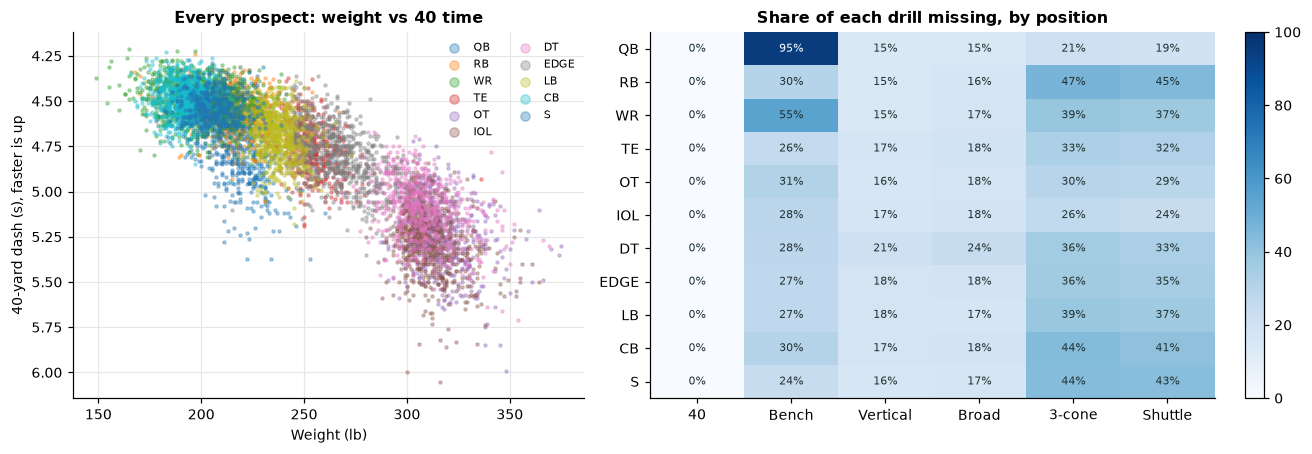

Modelling sample: 7,690 prospects, 5,081 drafted; 23.7% of drill results missing


In [4]:
display(summaries.sample_census(df).round(2))
plots.sample_overview(df, summaries.drill_missing_by_position(df))
plt.show()
print(f"Modelling sample: {len(df):,} prospects, {df.drafted.sum():,} drafted; "
      f"{df[prepare.DRILLS].isna().values.mean():.1%} of drill results missing")

## 3. Features: size- and era-adjusted drill scores
A 4.9-second 40 is slow for a receiver and remarkable for a nose tackle, and even within a position heavier players
run slower. So for each position and drill we fit a regression on players who actually ran it:

$$\text{drill} = \beta_0 + \beta_1\,\text{height} + \beta_2\,\text{weight} + \beta_3\,\text{weight}^2 + \beta_4\,\text{year} + \beta_5\,\mathbf{1}[\text{2021}] + \varepsilon$$

The residual says how much better or worse a player tested than his size and era predict. It is then scaled
**robustly** (median and MAD instead of mean and SD, so the outliers we are hunting don't distort the yardstick)
and flipped so that **positive always means better**. 2021 gets its own term because there was no combine that
year; its numbers are hand-timed pro-day results.

**Missing drills** are filled by iterative imputation within position (each drill predicted from the others).
Imputed values sit near the middle of the distribution, so imputation can only make a player look *less* unusual.

The **athleticism composite** (`ath_z`) is the average of a player's adjusted drill scores, standardized within position.

In [5]:
df = features.adjust_drills(df)
display(summaries.fastest_for_size(df).round(2))

,player_name,season,grp,ht,wt,forty,z_ht,z_wt,adj_forty,adj_vertical,ath_z
3091,Bruce Campbell,2010,OT,78,314,4.750,0.000,0.100,3.200,1.220,1.790
1874,Vernon Davis,2006,TE,75,254,4.380,-0.670,0.220,3.160,2.870,3.450
3986,Terron Armstead,2013,OT,77,306,4.710,-0.670,-0.670,3.030,1.900,1.980
6673,Jordan Davis,2022,DT,78,341,4.780,2.020,2.620,2.960,1.730,3.080
851,Donte' Stallworth,2002,WR,72,197,4.220,-0.340,-0.250,2.940,0.970,1.860
1543,Elton Brown,2005,IOL,77,329,4.930,0.670,1.930,2.940,0.870,2.190
4105,Lane Johnson,2013,OT,78,303,4.720,0.000,-0.960,2.890,1.590,2.370
6501,Jayson Oweh,2021,EDGE,77,257,4.360,1.350,-0.340,2.880,1.970,2.700


## 4. Primary method: robust Mahalanobis distance
**Idea.** For each prospect we ask: *how far is this profile from the centre of his position group, measured in
units that respect how the measurements normally move together?* That is the Mahalanobis distance:

$$D^2(\mathbf{x}) = (\mathbf{x}-\boldsymbol\mu)^\top \boldsymbol\Sigma^{-1} (\mathbf{x}-\boldsymbol\mu)$$

Plain Euclidean distance would treat "fast" and "explosive" as independent surprises. They aren't: fast players
usually jump well. Dividing by the covariance $\boldsymbol\Sigma$ means that a player who is fast **but not**
explosive, or heavy **and** fast, gets a large distance. Unusual *combinations* are what make a unicorn.

**Why robust.** If $\boldsymbol\mu$ and $\boldsymbol\Sigma$ were ordinary means and covariances, the unicorns
themselves would stretch them and hide. The **Minimum Covariance Determinant** (MCD) estimator fits the centre and
shape on the tightest 85% of players only, so the outliers are measured against a clean "normal" range.

**Two views per position.**
- *Full workout*: height, weight and every adjusted drill (some imputed).
- *Size–speed*: height, weight and adjusted 40 only, all measured for everyone. This catches players such as
  Calvin Johnson, whose only recorded drill is the 40.

Each view's $D^2$ is turned into a percentile within the position. A player's **unicorn score** is the higher of
his two percentiles, re-ranked; the top 5% are **unicorns**. Under normality $D^2$ follows a $\chi^2$ distribution
with as many degrees of freedom as features, which gives a second, model-based cutoff we use as a robustness check.

In [6]:
df = detect.score_prospects(df)
display(summaries.unicorn_counts(df))
print(f"{df.unicorn.sum()} unicorns: " + ", ".join(f"{(df.utype == t).sum()} {t}" for t in detect.UNICORN_TYPES))

utype,Freak,Odd build,Red flag,Typical
grp,,,,
QB,7,7,7,392
RB,5,14,18,679
WR,19,22,17,1098
TE,4,11,8,429
OT,6,13,12,577
IOL,9,14,13,686
DT,10,14,6,574
EDGE,14,14,13,785
LB,7,14,15,682


388 unicorns: 99 Freak, 153 Odd build, 136 Red flag


### Does the χ² assumption hold?
If profiles were multivariate normal, the robust $D^2$ would line up with the χ² line in a Q–Q plot. The tails bend
upward: real athletes produce more extreme profiles than a normal model expects. That is why we flag by **percentile
rank within position** (a fixed 5% per group) rather than a χ² p-value, and keep the χ² cutoff as a sensitivity check.

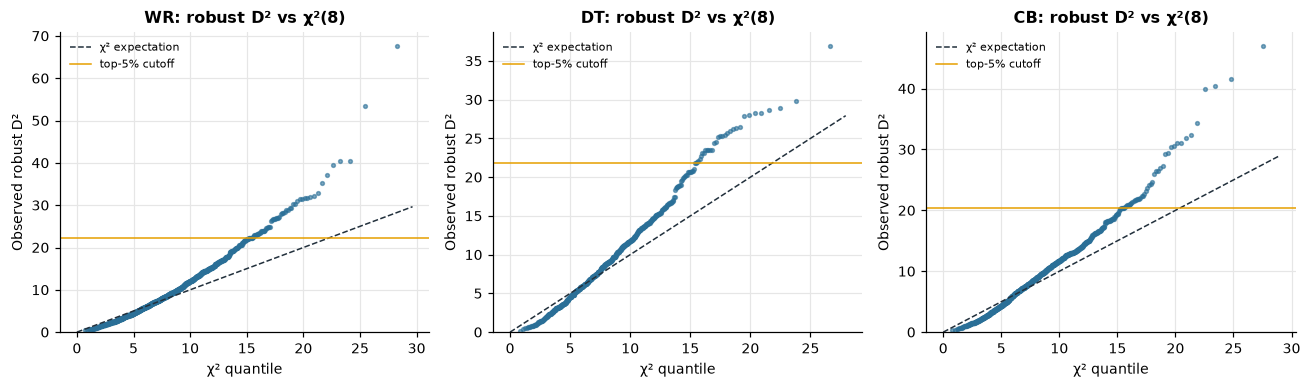

Share of prospects beyond the χ² 97.5% point (full view): 9.2%  (normal theory expects 2.5%)


In [7]:
plots.chi2_qq(df)
plt.show()
share_chi = summaries.share_beyond_chi2(df)
print(f"Share of prospects beyond the χ² 97.5% point (full view): {share_chi:.1%}  (normal theory expects 2.5%)")

### Where the unicorns are
Weight vs 40 time for three positions. Grey is the normal range; coloured points are flagged. Some flagged players
sit inside the cloud here because they are unusual on drills this 2-D picture doesn't show.

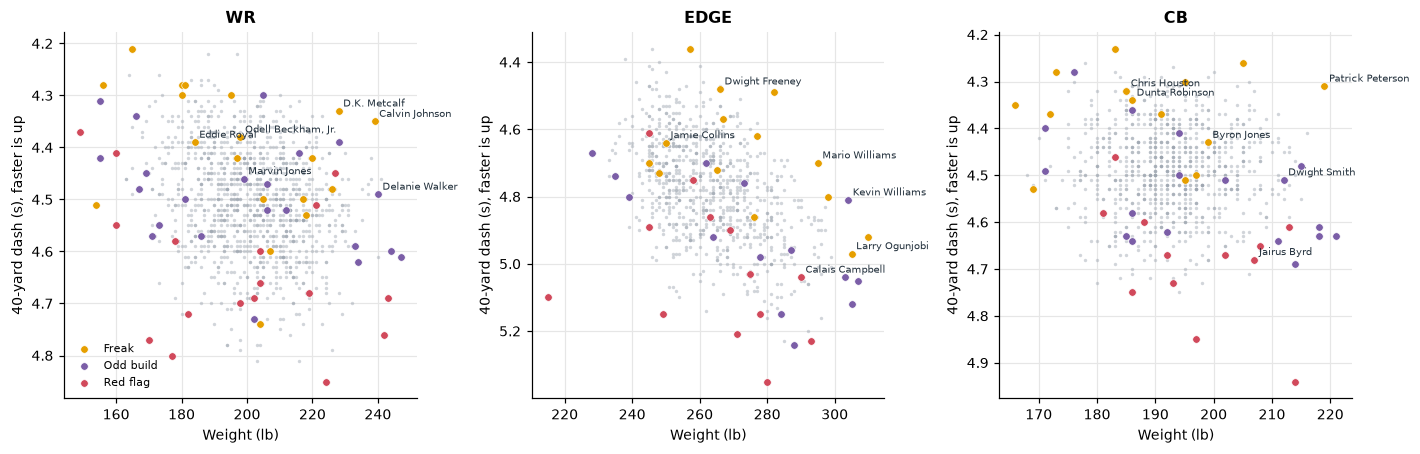

In [8]:
plots.unicorn_scatter(df)
plt.show()

# We're excited to work on the future of this project over the coming weeks!